# Praktikum 1 - JST 2 Layer dengan Forward Pass dan Backpropagation Manual

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-1)

Kode utama mengikuti blok kode modul tanpa perubahan logika: dataset XOR, 2 neuron hidden, sigmoid, `lr = 0.1`, dan 10.000 epoch.
Satu-satunya tambahan adalah `np.random.seed(42)` agar bobot awal dan hasilnya reprodusibel. Evaluasi classifier dan Tugas 1 diletakkan setelah langkah modul.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Langkah 1-5 - Dataset XOR, inisialisasi, forward pass, backpropagation, update bobot (kode modul)

In [2]:
import numpy as np
np.random.seed(42)

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2558299419444368
Epoch 1000, Loss: 0.2494056595655124
Epoch 2000, Loss: 0.24544465159719797
Epoch 3000, Loss: 0.20470733040714417
Epoch 4000, Loss: 0.15320405369970766
Epoch 5000, Loss: 0.13869146014771938
Epoch 6000, Loss: 0.1335936332185176
Epoch 7000, Loss: 0.13115112181268007
Epoch 8000, Loss: 0.12974916048385188
Epoch 9000, Loss: 0.12884908965171127
Prediksi:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


`sigmoid_derivative(x)` menerima keluaran sigmoid (`a`), bukan pra-aktivasi. Karena σ'(z) = σ(z)(1 − σ(z)), pemanggilan
`sigmoid_derivative(a2)` dan `sigmoid_derivative(a1)` pada modul sudah benar. Error ditulis `y − a2`, sehingga pembaruan bobot memakai `+=`.
Ini setara dengan gradient descent pada MSE.

## Evaluasi classifier

Materi JS13 bagian 1 membahas confusion matrix, accuracy, precision, recall, dan F1. Keluaran sigmoid dibulatkan dengan threshold 0,5.

,x1,x2,target,probabilitas,prediksi
0,0,0,0,0.0530,0
1,0,1,1,0.4955,0
2,1,0,1,0.9509,1
3,1,1,0,0.5032,1


Accuracy=0.50  Precision=0.50  Recall=0.50  F1=0.50


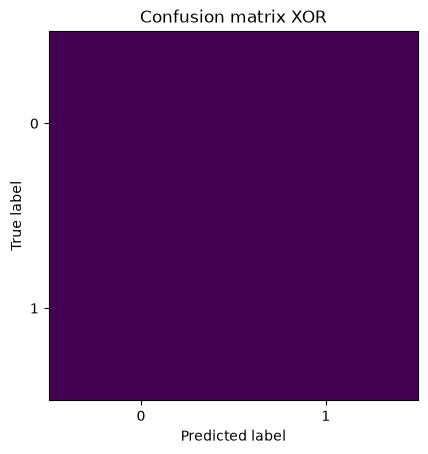

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

pred = (a2 > 0.5).astype(int)
display(pd.DataFrame({'x1': X[:, 0], 'x2': X[:, 1], 'target': y.ravel(), 'probabilitas': a2.ravel().round(4), 'prediksi': pred.ravel()}))
print(f"Accuracy={accuracy_score(y, pred):.2f}  Precision={precision_score(y, pred, zero_division=0):.2f}  "
      f"Recall={recall_score(y, pred):.2f}  F1={f1_score(y, pred):.2f}")
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot(colorbar=False); plt.title('Confusion matrix XOR'); plt.show()

## Tugas 1

* Ubah jumlah neuron hidden layer menjadi 3.
* Bandingkan hasil loss dengan konfigurasi awal.
* Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.

Kode modul dibungkus menjadi fungsi `train_xor` dengan algoritme identik. ReLU dipasang di hidden layer, sedangkan output tetap sigmoid
karena target XOR biner. Turunan ReLU dihitung dari pra-aktivasi `z1`. JST sekecil ini sangat sensitif terhadap bobot awal:
dengan 2 neuron, XOR bisa terjebak di minimum lokal. Karena itu tiap konfigurasi dijalankan dengan **20 seed** dan dicatat berapa run yang berhasil.
Run dianggap berhasil jika keempat prediksi benar.

In [4]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(z):
    return (z > 0).astype(float)

def train_xor(hidden_size=2, activation='sigmoid', seed=42, epochs=10000, lr=0.1):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(input_size, hidden_size); b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, output_size); b2 = np.zeros((1, output_size))
    losses = []
    for epoch in range(epochs):
        z1 = np.dot(X, W1) + b1
        a1 = sigmoid(z1) if activation == 'sigmoid' else relu(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)
        error = y - a2
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2); d_b2 = np.sum(d_a2, axis=0, keepdims=True)
        d_hidden = sigmoid_derivative(a1) if activation == 'sigmoid' else relu_derivative(z1)
        d_a1 = np.dot(d_a2, W2.T) * d_hidden
        d_W1 = np.dot(X.T, d_a1); d_b1 = np.sum(d_a1, axis=0, keepdims=True)
        W1 += lr * d_W1; b1 += lr * d_b1; W2 += lr * d_W2; b2 += lr * d_b2
        losses.append(np.mean(np.square(error)))
    return np.array(losses), a2

configs = {'2 neuron, sigmoid (modul)': (2, 'sigmoid'), '3 neuron, sigmoid': (3, 'sigmoid'),
           '2 neuron, ReLU': (2, 'relu'), '3 neuron, ReLU': (3, 'relu')}
seeds = range(20)
rows, curves = [], {}
for name, (h, act) in configs.items():
    for s in seeds:
        losses, out = train_xor(h, act, seed=s)
        ok = np.array_equal((out > 0.5).astype(int), y)
        epoch_lt_001 = int(np.argmax(losses < 0.01)) if (losses < 0.01).any() else np.nan
        rows.append({'konfigurasi': name, 'seed': s, 'loss_1000': losses[1000], 'loss_akhir': losses[-1],
                     'epoch_loss<0.01': epoch_lt_001, 'berhasil': ok})
        if s == 42 % 20: curves[name] = losses
res = pd.DataFrame(rows)
summary = res.groupby('konfigurasi', sort=False).agg(
    loss_1000_median=('loss_1000', 'median'), loss_akhir_median=('loss_akhir', 'median'),
    loss_akhir_mean=('loss_akhir', 'mean'), epoch_loss_lt_001_median=('epoch_loss<0.01', 'median'),
    run_berhasil=('berhasil', 'sum'))
summary['run_berhasil'] = summary['run_berhasil'].astype(int).astype(str) + ' / 20'
summary.round(5)

,loss_1000_median,loss_akhir_median,loss_akhir_mean,epoch_loss_lt_001_median,run_berhasil
konfigurasi,,,,,
"2 neuron, sigmoid (modul)",0.24332,0.00418,0.03465,6196.0,15 / 20
"3 neuron, sigmoid",0.23102,0.00233,0.00248,4969.5,20 / 20
"2 neuron, ReLU",0.16730,0.16669,0.17714,835.5,2 / 20
"3 neuron, ReLU",0.12605,0.12505,0.09805,832.0,9 / 20


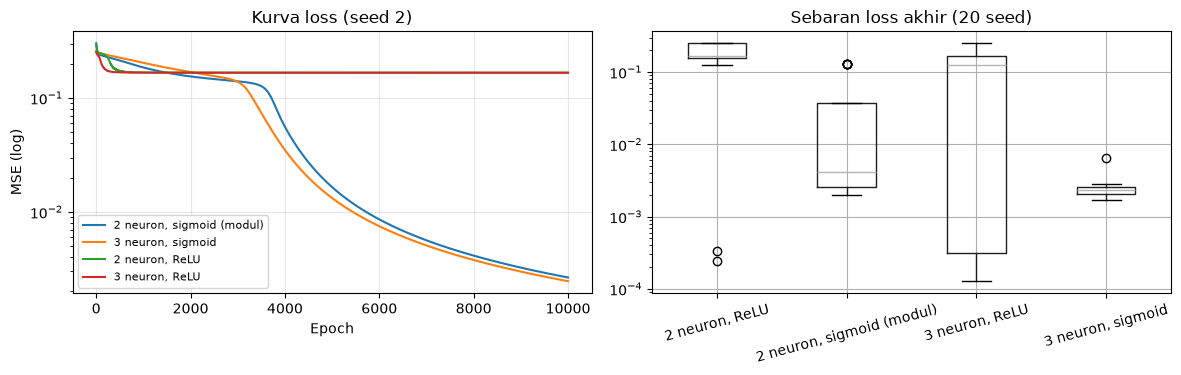

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, c in curves.items():
    ax[0].plot(c, label=name)
ax[0].set_yscale('log'); ax[0].set_title('Kurva loss (seed 2)'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE (log)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
res.boxplot(column='loss_akhir', by='konfigurasi', ax=ax[1], rot=15)
ax[1].set_yscale('log'); ax[1].set_title('Sebaran loss akhir (20 seed)'); ax[1].set_xlabel('')
plt.suptitle(''); plt.tight_layout(); plt.show()

## Analisis Tugas 1

**Hasil kode modul (seed 42).** Loss turun dari 0,256 ke 0,129, lalu stagnan. Prediksi untuk (0,1) dan (1,1) tertahan di sekitar 0,50, sehingga akurasi XOR hanya 50% (2 dari 4 benar). Prediksi (0,0) = 0,05 dan (1,0) = 0,95 sudah benar, tetapi (0,1) dan (1,1) tertahan di sekitar 0,50, sehingga jaringan 2-2-1 ini terjebak di **minimum lokal** (titik datar). Penurunan loss setelah epoch 6.000 sangat lambat (0,134 → 0,129). Run ini menunjukkan mengapa XOR menjadi contoh klasik. Data XOR tidak dapat dipisahkan secara linier (Minsky & Papert, 1969) sehingga butuh hidden layer yang dilatih dengan backpropagation (Rumelhart dkk., 1986), dan dengan hanya 2 neuron hasilnya sangat bergantung pada bobot awal.

**Perbandingan pada 20 seed:**

| Konfigurasi | Run berhasil (4/4 benar) | Median loss akhir | Median epoch hingga loss < 0,01 |
| --- | --- | --- | --- |
| 2 neuron, sigmoid (modul) | 15/20 | 0,0042 | 6.196 |
| **3 neuron, sigmoid** | **20/20** | **0,0023** | 4.970 |
| 2 neuron, ReLU | 2/20 | 0,1667 | 836 |
| 3 neuron, ReLU | 9/20 | 0,1251 | 832 |

1. **Hidden 2 → 3 neuron (sigmoid).** Konfigurasi 3 neuron selalu berhasil (20/20) dan loss akhirnya lebih kecil (median 0,0023 vs 0,0042; rata-rata 0,0025 vs 0,0347). Neuron tambahan memberi jalur alternatif ketika satu neuron jenuh, sehingga permukaan loss memiliki lebih sedikit minimum lokal yang buruk. Hasil ini sejalan dengan pengamatan bahwa jaringan yang sedikit lebih lebar lebih mudah dioptimasi.
2. **Sigmoid → ReLU.** Ketika berhasil, ReLU konvergen jauh lebih cepat: loss < 0,01 dicapai pada sekitar 830 epoch, sekitar 6-7 kali lebih cepat daripada sigmoid. Turunan ReLU bernilai 1 pada daerah aktif sehingga gradien tidak mengecil, sesuai temuan Nair & Hinton (2010) dan Glorot dkk. (2011). Namun pada XOR yang hanya punya 4 titik dan 2-3 neuron, ReLU **sering gagal** (2/20 dan 9/20). Neuron ReLU yang pra-aktivasinya negatif untuk semua input tidak pernah aktif lagi (gradien 0). Fenomena *dying ReLU* ini dianalisis oleh Lu dkk. (2020): peluang seluruh neuron mati tinggi pada jaringan yang sempit. Neuron yang lebih banyak (3 vs 2) menurunkan peluang tersebut, seperti terlihat dari kenaikan 2/20 → 9/20.

**Kesimpulan:** untuk JST sangat kecil seperti pada modul, sigmoid dengan 3 neuron paling andal. ReLU unggul dalam kecepatan konvergensi, tetapi membutuhkan lebar jaringan atau inisialisasi yang lebih baik (misalnya He initialization) agar tidak mati. Karena itu ReLU menjadi default pada jaringan yang lebih besar, seperti pada Praktikum 2 dan Tugas.

## Rujukan

1. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature*, 323(6088), 533-536. https://doi.org/10.1038/323533a0
2. Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
3. Nair, V., & Hinton, G. E. (2010). Rectified linear units improve restricted Boltzmann machines. *Proceedings of the 27th International Conference on Machine Learning (ICML)*, 807-814.
4. Glorot, X., Bordes, A., & Bengio, Y. (2011). Deep sparse rectifier neural networks. *Proceedings of the 14th International Conference on Artificial Intelligence and Statistics (AISTATS)*, PMLR 15, 315-323.
5. Lu, L., Shin, Y., Su, Y., & Karniadakis, G. E. (2020). Dying ReLU and initialization: Theory and numerical examples. *Communications in Computational Physics*, 28(5), 1671-1706. https://doi.org/10.4208/cicp.OA-2020-0165
6. Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, 45(4), 427-437. https://doi.org/10.1016/j.ipm.2009.03.002